In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
# 1. Load Data
train1 = pd.read_csv("../data/case1/train1.csv")
test1 = pd.read_csv("../data/case1/test1.csv")

In [5]:
# 2. Feature Engineering Function
def add_feature_combinations(df):
    df = df.copy()
    
    df['speed_krpm'] = df['speed_rpm'] / 1000.0
    df['delta_p'] = df['outlet_pressure_bar'] - df['inlet_pressure_bar']
    
    df['speed_x_delta_p'] = df['speed_krpm'] * df['delta_p']      # interaction
    df['power_per_speed'] = df['power_w'] / (df['speed_krpm'] + 1e-6)  # power ratio
    df['speed_sq'] = df['speed_krpm'] ** 2                         # quadratic speed
    df['delta_p_sq'] = df['delta_p'] ** 2                          # quadratic pressure
    df['power_sq'] = df['power_w'] ** 2                            # quadratic power
    return df

In [6]:
train1_fe = add_feature_combinations(train1)
test1_fe = add_feature_combinations(test1)

In [7]:
y_train = train1_fe['flow_m3_h']
y_test = test1_fe['flow_m3_h']

In [9]:
# 3. Define Candidate Feature Sets to Compare via CV
feature_sets = {
    'Set 1: Raw Features': ['speed_krpm', 'power_w', 'delta_p'],
    'Set 2: + Interactions': ['speed_krpm', 'power_w', 'delta_p', 'speed_x_delta_p', 'power_per_speed'],
    'Set 3: + Quadratic Terms': ['speed_krpm', 'power_w', 'delta_p', 'speed_x_delta_p', 'power_per_speed', 'speed_sq', 'delta_p_sq'],
    'Set 4: + Quadratic Power (Full)': ['speed_krpm', 'power_w', 'delta_p', 'speed_x_delta_p', 'power_per_speed', 'speed_sq', 'delta_p_sq', 'power_sq']
}

In [10]:
# 4. Run 5-Fold Cross-Validation on train1
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("=== 5-FOLD CROSS-VALIDATION ON TRAIN1 ===")
for name, cols in feature_sets.items():
    scores = cross_val_score(
        LinearRegression(), 
        train1_fe[cols], 
        y_train, 
        cv=cv, 
        scoring='neg_root_mean_squared_error'
    )
    mean_rmse = -scores.mean()
    std_rmse = scores.std()
    cv_results[name] = (mean_rmse, cols)
    print(f"{name:32s} | CV RMSE: {mean_rmse:.4f} ± {std_rmse:.4f} m³/h")

=== 5-FOLD CROSS-VALIDATION ON TRAIN1 ===
Set 1: Raw Features              | CV RMSE: 3.4800 ± 0.1603 m³/h
Set 2: + Interactions            | CV RMSE: 1.1398 ± 0.0450 m³/h
Set 3: + Quadratic Terms         | CV RMSE: 1.1420 ± 0.0570 m³/h
Set 4: + Quadratic Power (Full)  | CV RMSE: 1.0979 ± 0.0618 m³/h


In [11]:
# 5. Select Best Feature Set Automatically Based on CV
best_set_name = min(cv_results, key=lambda k: cv_results[k][0])
best_cols = cv_results[best_set_name][1]
print(f"\n-> Selected Best Feature Set: {best_set_name}")


-> Selected Best Feature Set: Set 4: + Quadratic Power (Full)


In [12]:
# 6. Fit Final Model on train1 & Evaluate on test1
final_model = LinearRegression()
final_model.fit(train1_fe[best_cols], y_train)
y_pred = final_model.predict(test1_fe[best_cols])

residuals = y_test - y_pred
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
test_max_ae = np.max(np.abs(residuals))

print("\n=== FINAL HELD-OUT TEST1 EVALUATION ===")
print(f"Test RMSE : {test_rmse:.4f} m³/h")
print(f"Test MAE  : {test_mae:.4f} m³/h")
print(f"Test R²   : {test_r2:.4f}")
print(f"Max AE    : {test_max_ae:.4f} m³/h")

print("\n=== BEST MODEL PARAMETERS ===")
print(f"Intercept (beta_0): {final_model.intercept_:.6f}")
for col, coef in zip(best_cols, final_model.coef_):
    print(f"beta_{col:15s}: {coef:.6f}")


=== FINAL HELD-OUT TEST1 EVALUATION ===
Test RMSE : 1.0573 m³/h
Test MAE  : 0.8014 m³/h
Test R²   : 0.9923
Max AE    : 3.2160 m³/h

=== BEST MODEL PARAMETERS ===
Intercept (beta_0): -10.483272
beta_speed_krpm     : 6.565364
beta_power_w        : -0.065718
beta_delta_p        : -72.039078
beta_speed_x_delta_p: 9.660471
beta_power_per_speed: 0.354871
beta_speed_sq       : 0.709136
beta_delta_p_sq     : -0.083408
beta_power_sq       : 0.000004


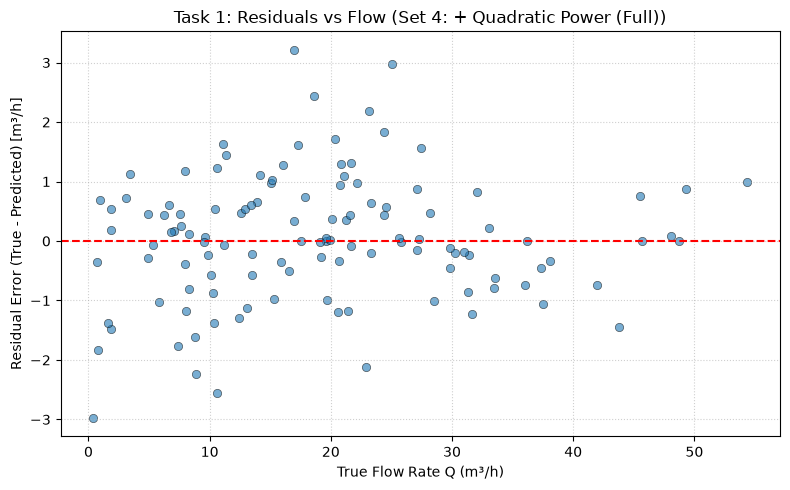

In [13]:
# 7.A: Residuals vs True Flow
plt.figure(figsize=(8, 5))
plt.scatter(y_test, residuals, alpha=0.6, color="#1f77b4", edgecolors="k", linewidth=0.5)
plt.axhline(0, color="red", linestyle="--", linewidth=1.5)
plt.xlabel("True Flow Rate Q (m³/h)")
plt.ylabel("Residual Error (True - Predicted) [m³/h]")
plt.title(f"Task 1: Residuals vs Flow ({best_set_name})")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

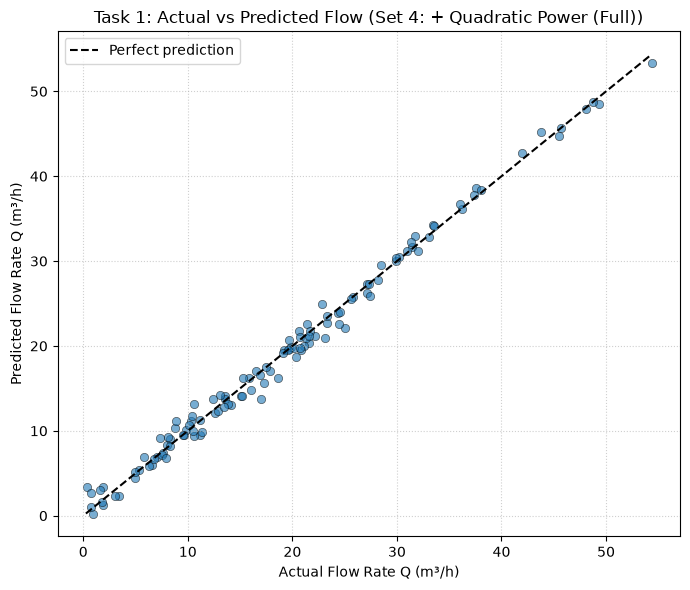

In [14]:
# 7.B: Actual vs Predicted Flow
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color="#1f77b4", edgecolors="k", linewidth=0.5)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "k--", linewidth=1.5, label="Perfect prediction")
plt.xlabel("Actual Flow Rate Q (m³/h)")
plt.ylabel("Predicted Flow Rate Q (m³/h)")
plt.title(f"Task 1: Actual vs Predicted Flow ({best_set_name})")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()